# Maternal Satisfaction ML Project
## Maternal Satisfaction Among Vaginal and Cesarean Section Delivery Care Services
### Bahir Dar City Health Facilities, Northwest Ethiopia
#### Application of Machine Learning (Logistic Regression)

**Dataset:** Delivery care satisfaction.sav (SPSS format)  
**Dependent Variable:** `satisfaction` (1 = Not Satisfied, 2 = Satisfied)  
**Algorithm:** Logistic Regression  


---
## Step 1: Import All Necessary Libraries

In [7]:
import pandas as pd
import numpy as np
import pyreadstat
import joblib
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss,
    confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
print('All libraries imported successfully.')


All libraries imported successfully.


---
## Step 2: Load the SPSS Dataset

In [8]:
# Load the SPSS (.sav) file using pyreadstat
data, meta = pyreadstat.read_sav('Delivery care satisfaction.sav')

print(f'Dataset loaded successfully.')
print(f'Shape: {data.shape[0]} observations x {data.shape[1]} variables')


Dataset loaded successfully.
Shape: 894 observations x 46 variables


---
## Step 3: Data Understanding
### 3.1 Variable Overview

In [9]:
# Display all column names
print('All variables in the dataset:')
for i, col in enumerate(data.columns, start=1):
    label = meta.column_names_to_labels.get(col, 'No label')
    print(f'  {i:2d}. {col:<40} {label}')


All variables in the dataset:
   1. q101age                                  None
   2. q102mstatu                               marital status
   3. q103religi                               religion
   4. q104ethini                               ethinicity
   5. q105educat                               educational status
   6. q106occupa                               occupation
   7. q107mincom                               monthly income
   8. q108reside                               residence
   9. q1091distk                               distance in kelometers
  10. q1092disth                               None
  11. q110reason                               reasons to visit hospital
  12. q111timeta                               time taken to get professionals
  13. q112waitpl                               presence of waiting area
  14. q113privac                               gender privacy during physical examination
  15. q201parity                               no of children
 

### 3.2 First and Last 5 Rows

In [10]:
data.head()

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,q110reason,q111timeta,q112waitpl,q113privac,q201parity,q202cpplan,q203ancatt,q204hivres,q205ga,q206delimo,q207nstatu,q208pdhsta,q209nsex,q2010bw,q301greeti,q302respec,q303delive,q411owners,ageafterrecod,monthlyincomerecode,gestationaagerecode,birthweightofbaby,satisfaction,modeofdeliveryrecode,waitingtimerecode,privacyrecode,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
0,22.00,2.00,1.00,1.00,4.00,88.00,800.00,2.00,0.00,200.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,41.00,1.00,1.00,1.00,1.00,1111.00,1.00,1.00,1.00,2.00,2.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00
1,35.00,2.00,1.00,3.00,4.00,2.00,7000.00,1.00,0.00,50.00,1.00,1.00,1.00,1.00,3.00,1.00,1.00,2.00,41.00,1.00,1.00,1.00,1.00,3000.00,1.00,1.00,1.00,2.00,3.00,4.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00
2,20.00,2.00,1.00,1.00,5.00,2.00,1500.00,1.00,5.00,NaN,1.00,1.00,1.00,1.00,2.00,1.00,1.00,2.00,42.00,1.00,1.00,1.00,1.00,3000.00,1.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,NaN
3,26.00,2.00,1.00,1.00,3.00,3.00,900.00,1.00,0.00,11.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,2.00,39.00,1.00,1.00,1.00,2.00,2600.00,1.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00
4,22.00,2.00,2.00,1.00,6.00,5.00,1536.00,2.00,5.00,NaN,2.00,1.00,2.00,1.00,2.00,1.00,1.00,2.00,39.00,2.00,2.00,2.00,1.00,2800.00,1.00,1.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,NaN


In [11]:
data.tail()

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,q110reason,q111timeta,q112waitpl,q113privac,q201parity,q202cpplan,q203ancatt,q204hivres,q205ga,q206delimo,q207nstatu,q208pdhsta,q209nsex,q2010bw,q301greeti,q302respec,q303delive,q411owners,ageafterrecod,monthlyincomerecode,gestationaagerecode,birthweightofbaby,satisfaction,modeofdeliveryrecode,waitingtimerecode,privacyrecode,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
889,29.00,3.00,2.00,2.00,6.00,88.00,2200.00,1.00,30.00,NaN,2.00,2.00,2.00,2.00,2.00,1.00,1.00,3.00,41.00,2.00,1.00,1.00,1.00,3600.00,1.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
890,31.00,2.00,1.00,1.00,7.00,1.00,4530.00,1.00,20.00,NaN,2.00,1.00,2.00,2.00,2.00,2.00,2.00,3.00,37.00,2.00,1.00,1.00,1.00,2900.00,2.00,2.00,2.00,2.00,3.00,3.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
891,21.00,2.00,1.00,1.00,6.00,3.00,2500.00,1.00,0.00,1.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,3.00,43.00,2.00,1.00,2.00,2.00,3000.00,2.00,2.00,2.00,2.00,2.00,2.00,3.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,NaN
892,18.00,1.00,2.00,1.00,7.00,1.00,3230.00,1.00,15.00,NaN,1.00,2.00,2.00,2.00,1.00,1.00,1.00,2.00,43.00,1.00,1.00,1.00,1.00,2001.00,1.00,2.00,2.00,2.00,1.00,3.00,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
893,22.00,3.00,2.00,4.00,6.00,2.00,1500.00,1.00,10.00,1.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,2.00,37.00,1.00,1.00,1.00,2.00,3100.00,1.00,1.00,2.00,2.00,2.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,NaN


### 3.3 Data Types and Non-Null Counts

In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 894 entries, 0 to 893
Data columns (total 46 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   q101age                                894 non-null    float64
 1   q102mstatu                             894 non-null    float64
 2   q103religi                             894 non-null    float64
 3   q104ethini                             894 non-null    float64
 4   q105educat                             894 non-null    float64
 5   q106occupa                             894 non-null    float64
 6   q107mincom                             894 non-null    float64
 7   q108reside                             894 non-null    float64
 8   q1091distk                             894 non-null    float64
 9   q1092disth                             320 non-null    float64
 10  q110reason                             894 non-null    float64
 11  q111timeta       

### 3.4 Missing Values

In [13]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing (%)': missing_pct
})
print('Variables with missing values:')
print(missing_df[missing_df['Missing Count'] > 0].to_string())
print(f'\nTotal missing values: {missing.sum()}')
print(f'Total complete rows: {data.dropna().shape[0]}')


Variables with missing values:
                            Missing Count  Missing (%)
q1092disth                            574        64.21
wolkingdistancerecodeinhrs            619        69.24

Total missing values: 1193
Total complete rows: 275


### 3.5 Duplicate Rows

In [14]:
print('Number of duplicate rows:', data.duplicated().sum())


Number of duplicate rows: 0


### 3.6 Value Labels from SPSS Metadata

In [15]:
# Show SPSS value labels for all categorical variables
for col in data.columns:
    labels = meta.variable_value_labels.get(col)
    if labels:
        print(f'\n{col}')
        print('-' * 40)
        for code, label in labels.items():
            print(f'  {code} = {label}')



q102mstatu
----------------------------------------
  1.0 = single
  2.0 = married
  3.0 = cohabited
  4.0 = widowed
  5.0 = divorced

q103religi
----------------------------------------
  1.0 = orthodox
  2.0 = muslim
  3.0 = protestant
  4.0 = orhers

q104ethini
----------------------------------------
  1.0 = amhara
  2.0 = oromo
  3.0 = tigrie
  4.0 = agew
  88.0 = others

q105educat
----------------------------------------
  1.0 = able to read and write
  2.0 = unable to read and write
  3.0 = grade 1 to 4
  4.0 = grade 5 to 8
  5.0 = grade 9 to 10
  6.0 = grade 11 to 12
  7.0 = diploma and above

q106occupa
----------------------------------------
  1.0 = governmental
  2.0 = merchants
  3.0 = huose wife
  4.0 = farmer
  5.0 = students
  88.0 = others

q108reside
----------------------------------------
  1.0 = urban
  2.0 = rural

q110reason
----------------------------------------
  1.0 = planed
  2.0 = refered

q111timeta
----------------------------------------
  1.0 = <1hr


### 3.7 Variable Summary Table

In [16]:
variable_summary = pd.DataFrame({
    'Variable': data.columns,
    'Label': [meta.column_names_to_labels.get(c, '') for c in data.columns],
    'Data_Type': data.dtypes.astype(str).values,
    'Missing': data.isnull().sum().values,
    'Missing_%': (data.isnull().sum() / len(data) * 100).round(2).values,
    'Unique_Values': data.nunique().values
})
print(variable_summary.to_string(index=False))


                             Variable                                                                  Label Data_Type  Missing  Missing_%  Unique_Values
                              q101age                                                                    NaN   float64        0       0.00             24
                           q102mstatu                                                         marital status   float64        0       0.00              5
                           q103religi                                                               religion   float64        0       0.00              4
                           q104ethini                                                             ethinicity   float64        0       0.00              4
                           q105educat                                                     educational status   float64        0       0.00              7
                           q106occupa                                       

### 3.8 Target Variable Distribution

Satisfaction variable distribution:
  1.0 (not satisfied): 345 (38.6%)
  2.0 (satisfied): 549 (61.4%)


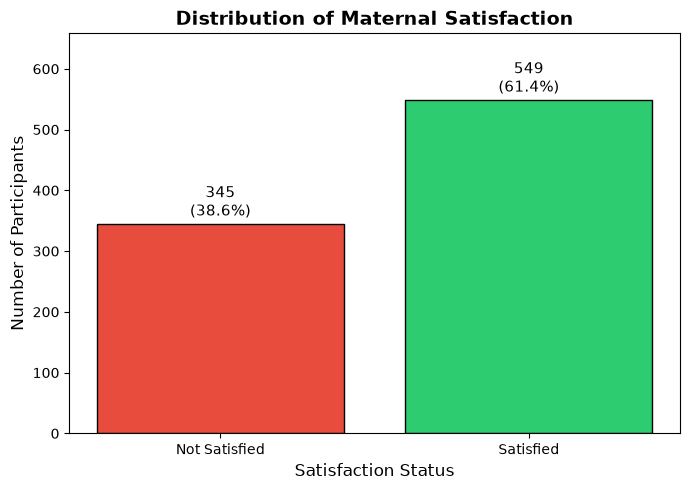

Class imbalance ratio (Not Satisfied : Satisfied) = 345 : 549


In [17]:
target_counts = data['satisfaction'].value_counts().sort_index()
target_pct = (data['satisfaction'].value_counts(normalize=True).sort_index() * 100).round(1)

print('Satisfaction variable distribution:')
for code, cnt in target_counts.items():
    label = meta.variable_value_labels['satisfaction'].get(code, str(code))
    print(f'  {code} ({label}): {cnt} ({target_pct[code]:.1f}%)')

# Bar chart
labels = ['Not Satisfied', 'Satisfied']
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, target_counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black')
for bar, cnt, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f'{cnt}\n({pct}%)', ha='center', va='bottom', fontsize=11)
ax.set_title('Distribution of Maternal Satisfaction', fontsize=14, fontweight='bold')
ax.set_xlabel('Satisfaction Status', fontsize=12)
ax.set_ylabel('Number of Participants', fontsize=12)
ax.set_ylim(0, max(target_counts.values) * 1.2)
plt.tight_layout()
plt.show()
print(f'Class imbalance ratio (Not Satisfied : Satisfied) = {target_counts[1.0]} : {target_counts[2.0]}')


---
## Step 4: Descriptive Statistics
### 4.1 Numerical Variables Summary

In [18]:
numerical_variables = [
    'q101age',    # Age of the mother
    'q107mincom', # Monthly income
    'q1091distk', # Distance in kilometers
    'q1092disth', # Distance in hours (has missing values)
    'q205ga',     # Gestational age (weeks)
    'q2010bw'     # Birth weight (grams)
]

num_summary = data[numerical_variables].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).T
num_summary.insert(2, 'variance', data[numerical_variables].var())
num_summary.columns = [
    'Count', 'Mean', 'Variance', 'Std', 'Min',
    'P10', 'P25', 'P50 (Median)', 'P75', 'P90', 'Max'
]
print('Descriptive Statistics - Numerical Variables')
print('=' * 80)
print(num_summary.round(2).to_string())


Descriptive Statistics - Numerical Variables
            Count    Mean    Variance     Std     Min     P10     P25  P50 (Median)     P75     P90      Max
q101age    894.00   26.60       23.83    4.88   17.00   20.00   23.00         27.00   30.00   33.00    42.00
q107mincom 894.00 4096.88 19983706.40 4470.31  200.00  853.00 1537.75       3000.00 5300.00 7650.00 50000.00
q1091distk 894.00   19.29     1956.16   44.23    0.00    0.00    0.00          5.00   15.00   50.00   500.00
q1092disth 320.00   16.67      282.75   16.82    1.00    2.00    4.00         12.00   30.00   30.00   200.00
q205ga     894.00   39.40        2.41    1.55   32.00   37.00   39.00         39.00   40.00   42.00    43.00
q2010bw    894.00 2941.73   292048.23  540.41 1111.00 2200.00 2600.00       2900.00 3200.00 3600.00  5001.00


### 4.2 Frequency Tables for Categorical Variables

In [19]:
categorical_variables = [
    'q102mstatu', 'q103religi', 'q104ethini', 'q105educat',
    'q106occupa', 'q108reside', 'q110reason', 'q111timeta',
    'q112waitpl', 'q113privac', 'q201parity', 'q202cpplan',
    'q203ancatt', 'q204hivres', 'q206delimo', 'q207nstatu',
    'q208pdhsta', 'q209nsex', 'q301greeti', 'q302respec',
    'q303delive', 'q411owners', 'ageafterrecod',
    'monthlyincomerecode', 'gestationaagerecode',
    'birthweightofbaby', 'modeofdeliveryrecode',
    'waitingtimerecode', 'privacyrecode',
    'encourageandsupportatdeliveryrecode', 'politenessrecode',
    'availabilityofmedicalequipmentsrecode', 'counselingrecode',
    'overallcleanessrecode', 'accessandcleanessoftoiletrecode',
    'waitingareacleanessandconfort', 'availabilityofbedintheward',
    'distancerecode1', 'wolkingdistancerecodeinhrs'
]

def labeled_frequency_table(df, variable, spss_meta):
    freq = df[variable].value_counts(dropna=False).sort_index()
    pct = (df[variable].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2)
    labels_map = spss_meta.variable_value_labels.get(variable, {})
    label_col = [labels_map.get(k, str(k)) for k in freq.index]
    table = pd.DataFrame({
        'Code': freq.index,
        'Label': label_col,
        'Frequency': freq.values,
        'Percentage (%)': pct.values
    })
    return table

for var in categorical_variables:
    label = meta.column_names_to_labels.get(var, var)
    print(f'\n{"-" * 60}')
    print(f'{var}: {label}')
    print(f'{"-" * 60}')
    print(labeled_frequency_table(data, var, meta).to_string(index=False))



------------------------------------------------------------
q102mstatu: marital status
------------------------------------------------------------
 Code     Label  Frequency  Percentage (%)
 1.00    single         98           10.96
 2.00   married        712           79.64
 3.00 cohabited         67            7.49
 4.00   widowed         10            1.12
 5.00  divorced          7            0.78

------------------------------------------------------------
q103religi: religion
------------------------------------------------------------
 Code      Label  Frequency  Percentage (%)
 1.00   orthodox        608           68.01
 2.00     muslim        193           21.59
 3.00 protestant         88            9.84
88.00       88.0          5            0.56

------------------------------------------------------------
q104ethini: ethinicity
------------------------------------------------------------
 Code  Label  Frequency  Percentage (%)
 1.00 amhara        715           79.98
 2

### 4.3 Key Visualizations

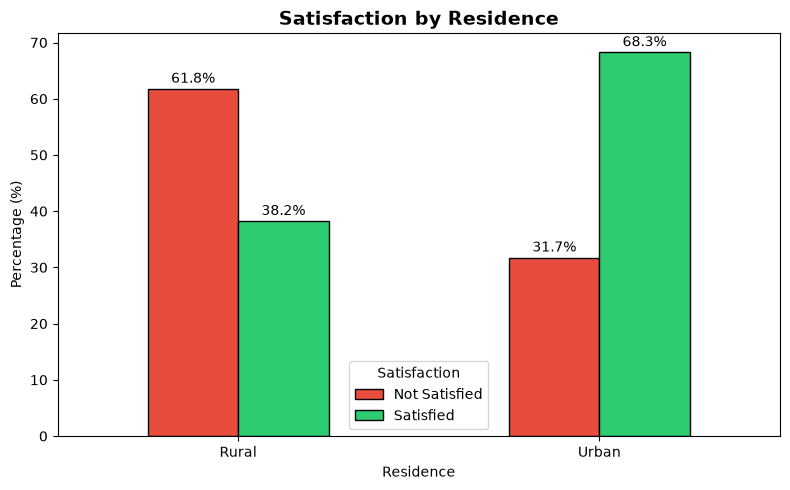

In [20]:
# Satisfaction by Residence
data['residence_label'] = data['q108reside'].map({1.0: 'Urban', 2.0: 'Rural'})
res_table = pd.crosstab(data['residence_label'], data['satisfaction'], normalize='index') * 100
res_table.columns = ['Not Satisfied', 'Satisfied']
ax = res_table.plot(kind='bar', figsize=(8, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=0)
ax.set_title('Satisfaction by Residence', fontsize=14, fontweight='bold')
ax.set_xlabel('Residence')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=2)
plt.tight_layout()
plt.show()


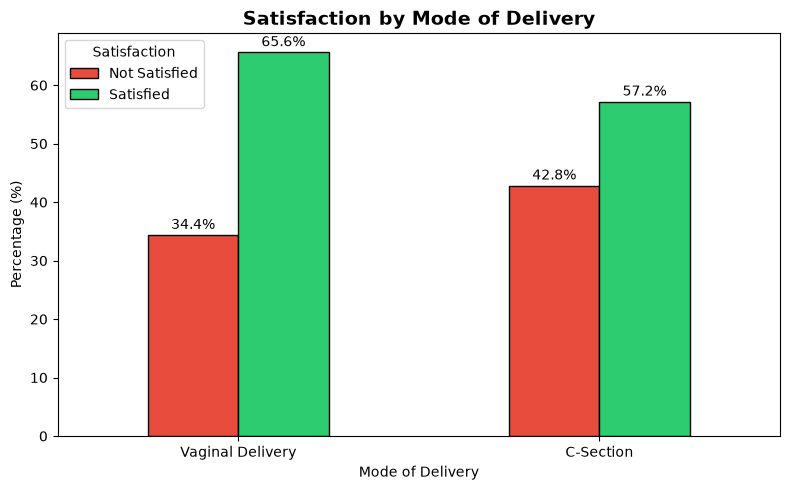

In [21]:
# Satisfaction by Mode of Delivery
del_table = pd.crosstab(data['modeofdeliveryrecode'],
                        data['satisfaction'], normalize='index') * 100
del_table.columns = ['Not Satisfied', 'Satisfied']
del_table.index = ['Vaginal Delivery', 'C-Section']
ax = del_table.plot(kind='bar', figsize=(8, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=0)
ax.set_title('Satisfaction by Mode of Delivery', fontsize=14, fontweight='bold')
ax.set_xlabel('Mode of Delivery')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=2)
plt.tight_layout()
plt.show()


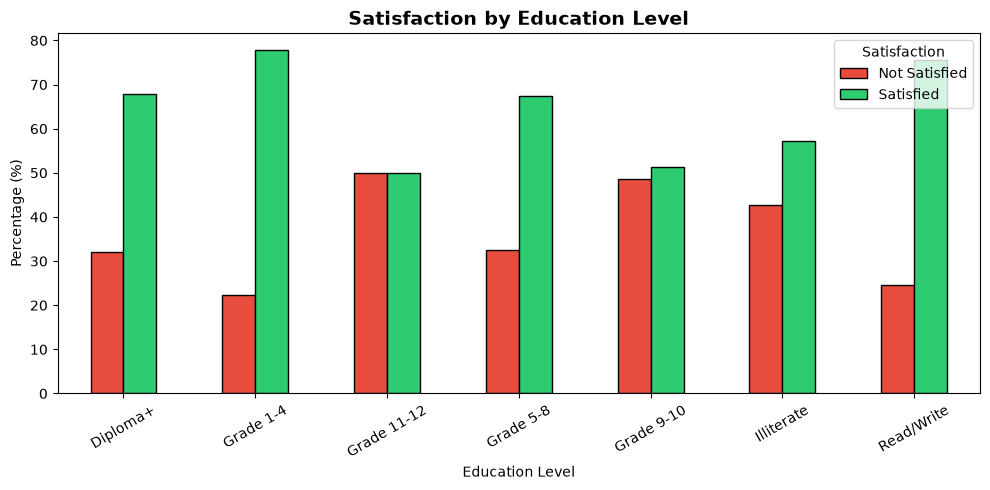

In [22]:
# Satisfaction by Education Level
edu_map = {
    1.0: 'Read/Write', 2.0: 'Illiterate', 3.0: 'Grade 1-4',
    4.0: 'Grade 5-8', 5.0: 'Grade 9-10', 6.0: 'Grade 11-12', 7.0: 'Diploma+'
}
data['edu_label'] = data['q105educat'].map(edu_map)
edu_table = pd.crosstab(data['edu_label'], data['satisfaction'], normalize='index') * 100
edu_table.columns = ['Not Satisfied', 'Satisfied']
ax = edu_table.plot(kind='bar', figsize=(10, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=30)
ax.set_title('Satisfaction by Education Level', fontsize=14, fontweight='bold')
ax.set_xlabel('Education Level')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
plt.tight_layout()
plt.show()


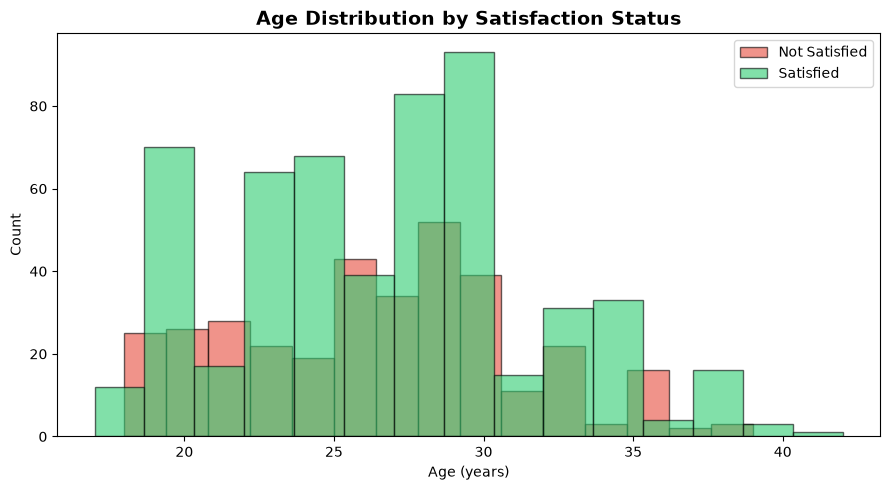

In [23]:
# Age distribution by Satisfaction
fig, ax = plt.subplots(figsize=(9, 5))
for sat_val, color, label in [(1.0, '#e74c3c', 'Not Satisfied'), (2.0, '#2ecc71', 'Satisfied')]:
    subset = data[data['satisfaction'] == sat_val]['q101age'].dropna()
    ax.hist(subset, bins=15, alpha=0.6, color=color, label=label, edgecolor='black')
ax.set_title('Age Distribution by Satisfaction Status', fontsize=14, fontweight='bold')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()


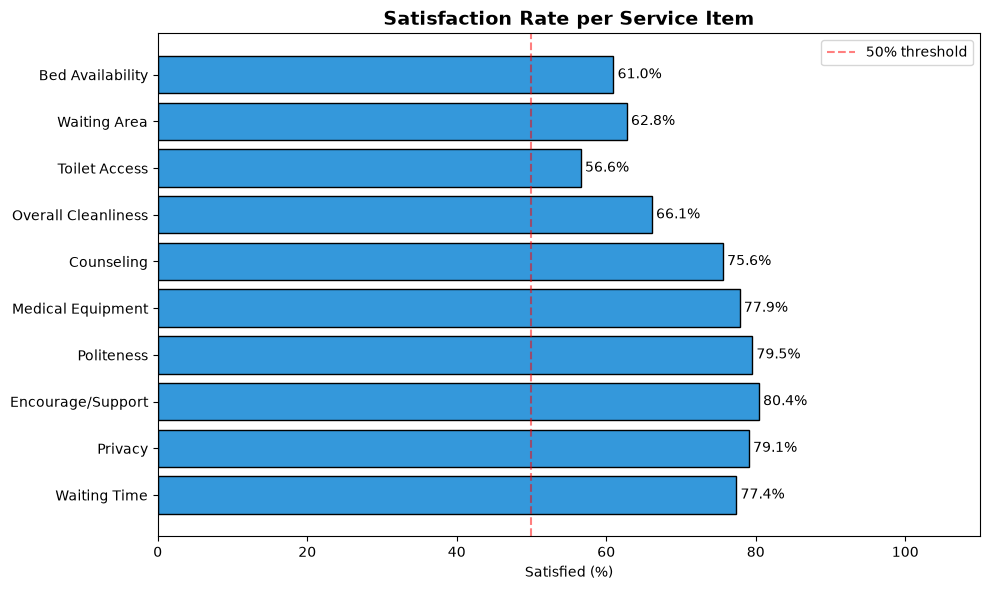

In [24]:
# Satisfaction-related service items
service_vars = [
    'waitingtimerecode', 'privacyrecode',
    'encourageandsupportatdeliveryrecode', 'politenessrecode',
    'availabilityofmedicalequipmentsrecode', 'counselingrecode',
    'overallcleanessrecode', 'accessandcleanessoftoiletrecode',
    'waitingareacleanessandconfort', 'availabilityofbedintheward'
]
service_labels = [
    'Waiting Time', 'Privacy', 'Encourage/Support',
    'Politeness', 'Medical Equipment', 'Counseling',
    'Overall Cleanliness', 'Toilet Access', 'Waiting Area', 'Bed Availability'
]

# Percentage satisfied per service item
sat_rates = [(data[v] == 2.0).mean() * 100 for v in service_vars]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(service_labels, sat_rates, color='#3498db', edgecolor='black')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlim(0, 110)
ax.set_title('Satisfaction Rate per Service Item', fontsize=14, fontweight='bold')
ax.set_xlabel('Satisfied (%)')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')
ax.legend()
plt.tight_layout()
plt.show()


---
## Step 5: Data Preparation & Feature Engineering

### 5.1 Encode Target Variable

In [25]:
# Recode: 1.0 (Not Satisfied) -> 0, 2.0 (Satisfied) -> 1
data['satisfaction_binary'] = data['satisfaction'].map({1.0: 0, 2.0: 1})
print('Target variable encoding:')
print('  1.0 (Not Satisfied) -> 0')
print('  2.0 (Satisfied)     -> 1')
print()
print(data['satisfaction_binary'].value_counts())


Target variable encoding:
  1.0 (Not Satisfied) -> 0
  2.0 (Satisfied)     -> 1

satisfaction_binary
1    549
0    345
Name: count, dtype: int64


### 5.2 Define Candidate Feature Set

Before selecting predictors, three categories of variables are excluded:

| # | Exclusion Rule | Variables Removed |
|---|---|---|
| 1 | **Target variable** | `satisfaction`, `satisfaction_binary` |
| 2 | **10 satisfaction sub-item recodes — data leakage** | `waitingtimerecode`, `privacyrecode`, `encourageandsupportatdeliveryrecode`, `politenessrecode`, `availabilityofmedicalequipmentsrecode`, `counselingrecode`, `overallcleanessrecode`, `accessandcleanessoftoiletrecode`, `waitingareacleanessandconfort`, `availabilityofbedintheward` |
| 3 | **>50 % missing values** | `q1092disth` (64.2 % missing), `wolkingdistancerecodeinhrs` (69.2 % missing) |
| 4 | **6 recoded variables** (keep original, drop the recode) | `ageafterrecod`, `monthlyincomerecode`, `gestationaagerecode`, `birthweightofbaby`, `modeofdeliveryrecode`, `distancerecode1` |

**Why remove the 10 satisfaction sub-items?**
Each of these variables is coded 1 = *not satisfied* / 2 = *satisfied* on a specific
service dimension (waiting time, privacy, cleanliness, etc.). They are direct
sub-components of the outcome variable `satisfaction`. Including them as predictors
causes **data leakage**: the model would learn to predict overall satisfaction from
sub-satisfaction ratings, inflating all metrics (AUC, accuracy, F1) to artificially
high values. The model would be useless in practice because those sub-ratings are
collected *at the same time* as the outcome, not before it.

After all exclusions **27 clean, independent candidate features** remain.

In [26]:
# ── Exclusions applied ───────────────────────────────────────────────────
# 1. Target : satisfaction, satisfaction_binary
# 2. 10 satisfaction sub-item recodes (data leakage) :
#       waitingtimerecode, privacyrecode,
#       encourageandsupportatdeliveryrecode, politenessrecode,
#       availabilityofmedicalequipmentsrecode, counselingrecode,
#       overallcleanessrecode, accessandcleanessoftoiletrecode,
#       waitingareacleanessandconfort, availabilityofbedintheward
# 3. >50 % missing : q1092disth, wolkingdistancerecodeinhrs
# 4. 6 recoded vars : ageafterrecod, monthlyincomerecode,
#       gestationaagerecode, birthweightofbaby,
#       modeofdeliveryrecode, distancerecode1
# ─────────────────────────────────────────────────────────────────────────────

candidate_features = [
    # Socio-demographic
    'q101age',       # Age of mother (continuous)
    'q102mstatu',    # Marital status
    'q103religi',    # Religion
    'q104ethini',    # Ethnicity
    'q105educat',    # Education level
    'q106occupa',    # Occupation
    'q107mincom',    # Monthly income (continuous)
    'q108reside',    # Residence (urban / rural)
    # Access to facility
    'q1091distk',    # Distance in km (continuous)
    'q110reason',    # Reason for visit (planned / referred)
    'q111timeta',    # Time to reach facility
    'q112waitpl',    # Waiting area present (yes / no)
    'q113privac',    # Privacy during examination (yes / no)
    # Obstetric history & outcome
    'q201parity',    # Parity (number of children)
    'q202cpplan',    # Current pregnancy planned
    'q203ancatt',    # ANC attendance
    'q204hivres',    # HIV status
    'q205ga',        # Gestational age in weeks (continuous)
    'q206delimo',    # Mode of delivery (raw)
    'q207nstatu',    # Neonatal outcome (alive / stillbirth)
    'q208pdhsta',    # Post-delivery health problem
    'q209nsex',      # Sex of baby
    'q2010bw',       # Birth weight in grams (continuous)
    # Care quality & facility
    'q301greeti',    # Professional greeted patient (yes / no)
    'q302respec',    # Respectful practice (yes / no)
    'q303delive',    # Sex of health care provider
    'q411owners',    # Facility ownership (private / government)
]

print(f'Candidate features after all exclusions: {len(candidate_features)}')
print()
missing_cand = data[candidate_features].isnull().sum()
missing_any  = missing_cand[missing_cand > 0]
if len(missing_any):
    print('Variables with missing values:')
    print(missing_any)
else:
    print('No missing values in any candidate feature.')

Number of candidate features: 37
Missing values in candidate features:
Series([], dtype: int64)

No missing values found.


### 5.3 Define Feature Types

Five variables are **numerical** (continuous); the remaining 22 are **categorical**
(SPSS-coded ordinal/nominal floats). Both types are handled in a single
`ColumnTransformer` pipeline.

In [27]:
numerical_features = [
    'q101age',    # Age (years)
    'q107mincom', # Monthly income (Birr)
    'q1091distk', # Distance to facility (km)
    'q205ga',     # Gestational age (weeks)
    'q2010bw',    # Birth weight (grams)
]

categorical_features = [c for c in candidate_features if c not in numerical_features]

print(f'Numerical features   ({len(numerical_features)}): {numerical_features}')
print(f'Categorical features ({len(categorical_features)}):')
for f in categorical_features:
    label = meta.column_names_to_labels.get(f, '')
    print(f'  {f:<20} {label}')

Categorical features: 37
Numerical features:   0


### 5.4 Prepare X and y

In [28]:
X = data[candidate_features].copy()
y = data['satisfaction_binary'].copy()

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Class distribution:')
print(y.value_counts())


X shape: (894, 37)
y shape: (894,)
Class distribution:
satisfaction_binary
1    549
0    345
Name: count, dtype: int64


### 5.5 Train / Test Split (80% / 20%, stratified)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(f'Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Test set:     {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)')
print()
print('Train class distribution:')
print(y_train.value_counts())
print('Test class distribution:')
print(y_test.value_counts())


Training set: 715 samples (80.0%)
Test set:     179 samples (20.0%)

Train class distribution:
satisfaction_binary
1    439
0    276
Name: count, dtype: int64
Test class distribution:
satisfaction_binary
1    110
0     69
Name: count, dtype: int64


---
## Step 6: Build Preprocessing Pipeline

A `ColumnTransformer` applies:
- **`StandardScaler`** to the 5 numerical features
- **`OneHotEncoder`** (`drop='first'`) to the 22 categorical features

Both transformers are fitted **only on training data** to prevent data leakage.

In [30]:
from sklearn.impute import SimpleImputer

# Numerical pipeline: impute median then scale
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# Categorical pipeline: impute mode then one-hot encode
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)),
])

preprocessor_full = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_features),
        ('cat', cat_pipeline, categorical_features),
    ],
    remainder='drop'
)

# Fit on training set, transform both sets
X_train_proc = preprocessor_full.fit_transform(X_train)
X_test_proc  = preprocessor_full.transform(X_test)

print('Processed training shape:', X_train_proc.shape)
print('Processed test shape:    ', X_test_proc.shape)

Processed training shape: (715, 60)
Processed test shape:     (179, 60)


---
## Step 7: Feature Selection

**Method:** 5-fold cross-validated permutation importance (ROC-AUC scoring).

For each fold we:
1. Train a Logistic Regression pipeline on 4 folds
2. Measure how much each feature hurts ROC-AUC when its values are randomly shuffled
3. Average the importance scores across all 5 folds

This avoids overfitting the feature ranking to a single train/test split.
The **top 10** features by mean importance are selected for the final model.

In [32]:
# 5-fold CV permutation importance on all 27 candidate features
cv_sel = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_importances = []

for fold, (tr_idx, val_idx) in enumerate(cv_sel.split(X_train, y_train), start=1):
    X_fold_tr  = X_train.iloc[tr_idx];  X_fold_val = X_train.iloc[val_idx]
    y_fold_tr  = y_train.iloc[tr_idx];  y_fold_val = y_train.iloc[val_idx]

    fold_num_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc',  StandardScaler()),
    ])
    fold_cat_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore')),
    ])
    fold_prep = ColumnTransformer([
        ('num', fold_num_pipe, numerical_features),
        ('cat', fold_cat_pipe, categorical_features),
    ])
    fold_model = Pipeline([
        ('preprocessor', fold_prep),
        ('classifier', LogisticRegression(
            max_iter=2000, class_weight='balanced', random_state=42
        )),
    ])

    fold_model.fit(X_fold_tr, y_fold_tr)

    perm = permutation_importance(
        fold_model, X_fold_val, y_fold_val,
        scoring='roc_auc', n_repeats=10, random_state=42 + fold
    )
    fold_importances.append(
        pd.Series(perm.importances_mean, index=candidate_features, name=f'fold_{fold}')
    )
    print(f'  Fold {fold} done.')

importance_by_fold = pd.concat(fold_importances, axis=1)

importance_df = pd.DataFrame({
    'Feature'        : candidate_features,
    'Label'          : [meta.column_names_to_labels.get(f, '') for f in candidate_features],
    'Importance_Mean': importance_by_fold.mean(axis=1).values,
    'Importance_Std' : importance_by_fold.std(axis=1).values,
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

importance_df.insert(0, 'Rank', range(1, len(importance_df) + 1))

print()
print('All 27 features ranked by permutation importance:')
print(importance_df.to_string(index=False))

Baseline model trained on all candidate features.
Baseline accuracy: 0.9441340782122905


In [33]:
fig, ax = plt.subplots(figsize=(10, 9))
colors = ['#2ecc71' if v >= 0 else '#e74c3c' for v in importance_df['Importance_Mean'][::-1]]
ax.barh(importance_df['Feature'][::-1],
        importance_df['Importance_Mean'][::-1],
        xerr=importance_df['Importance_Std'][::-1],
        color=colors, edgecolor='black')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Permutation Importance – All 27 Candidate Features (5-fold CV, ROC-AUC)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Mean Decrease in ROC-AUC')
plt.tight_layout()
plt.show()

Permutation Importance (top 20):
                              Feature  Importance_Mean  Importance_Std
           availabilityofbedintheward             0.00            0.00
        waitingareacleanessandconfort             0.00            0.00
      accessandcleanessoftoiletrecode             0.00            0.00
availabilityofmedicalequipmentsrecode             0.00            0.00
                overallcleanessrecode             0.00            0.00
                        privacyrecode             0.00            0.00
                    waitingtimerecode             0.00            0.00
                     politenessrecode             0.00            0.00
                           q106occupa             0.00            0.00
                           q110reason             0.00            0.00
                           q103religi             0.00            0.00
  encourageandsupportatdeliveryrecode             0.00            0.00
                           q111timeta       

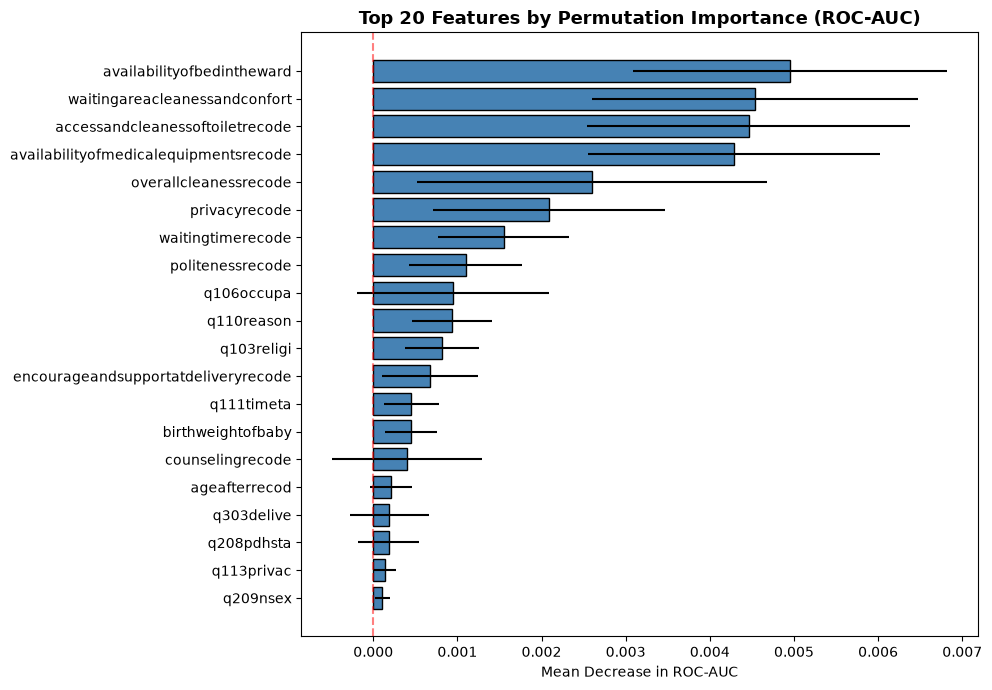

In [34]:
# Select the top 10 features by mean permutation importance
top10_features = importance_df.head(10)['Feature'].tolist()

print('Selected top 10 features:')
print('-' * 55)
for i, f in enumerate(top10_features, 1):
    label = meta.column_names_to_labels.get(f, '')
    imp   = importance_df.loc[importance_df['Feature'] == f, 'Importance_Mean'].values[0]
    print(f'  {i:2d}. {f:<20} mean_imp={imp:.5f}  {label}')

In [35]:
---
## Step 8: Build & Train Final Logistic Regression Model (Top 10 Features)

Selected top 10 features:
   1. availabilityofbedintheward                    availability of bed in the ward after recode
   2. waitingareacleanessandconfort                 waiting area cleaness and confort after recode
   3. accessandcleanessoftoiletrecode               access and cleaness of toilet after recode
   4. availabilityofmedicalequipmentsrecode         availability of medical equipments after recode
   5. overallcleanessrecode                         over all cleaness after recode
   6. privacyrecode                                 privacy after recode
   7. waitingtimerecode                             waiting time  after recode
   8. politenessrecode                              politeness after recode
   9. q106occupa                                    occupation
  10. q110reason                                    reasons to visit hospital


# Create reduced train/test sets using only the top-10 features
X_train_red = X_train[top10_features].copy()
X_test_red  = X_test[top10_features].copy()

print('Reduced training shape:', X_train_red.shape)
print('Reduced test shape:    ', X_test_red.shape)

In [36]:
# Identify types within the top-10
numerical_red   = [f for f in top10_features if f in numerical_features]
categorical_red = [f for f in top10_features if f not in numerical_features]

print(f'Numerical in top-10  : {numerical_red}')
print(f'Categorical in top-10: {categorical_red}')

# Build preprocessor for the reduced set
transformers_red = []
if numerical_red:
    transformers_red.append((
        'num',
        Pipeline([('imp', SimpleImputer(strategy='median')),
                  ('sc',  StandardScaler())]),
        numerical_red
    ))
if categorical_red:
    transformers_red.append((
        'cat',
        Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                  ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore',
                                        sparse_output=False))]),
        categorical_red
    ))

preprocessor_red = ColumnTransformer(transformers=transformers_red, remainder='drop')

final_model = Pipeline([
    ('preprocessor', preprocessor_red),
    ('classifier', LogisticRegression(
        max_iter=2000, class_weight='balanced',
        solver='lbfgs', random_state=42
    )),
])

final_model.fit(X_train_red, y_train)
print('Final Logistic Regression model trained successfully.')

Reduced training shape: (715, 10)
Reduced test shape:     (179, 10)


In [37]:
---
## Step 9: Hyperparameter Tuning (GridSearchCV)

We tune the regularisation strength `C` using 5-fold stratified cross-validation
on the **training set only**, scoring by ROC-AUC.

Final Logistic Regression model trained successfully.


param_grid  = {'classifier__C': [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]}
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    final_model,
    param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_red, y_train)

print('Best hyperparameter:', grid_search.best_params_)
print('Best CV ROC-AUC:    ', round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

In [38]:
---
## Step 10: Model Evaluation
### 10.1 Test Set Performance

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best hyperparameter: {'classifier__C': 1.0}
Best CV ROC-AUC:     0.9952


y_pred = best_model.predict(X_test_red)
y_prob = best_model.predict_proba(X_test_red)[:, 1]

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall    = recall_score(y_test, y_pred,    zero_division=0)
f1        = f1_score(y_test, y_pred,        zero_division=0)
roc_auc   = roc_auc_score(y_test, y_prob)
brier     = brier_score_loss(y_test, y_prob)

print('Model Performance Metrics')
print('=' * 48)
print(f'  Accuracy      : {accuracy:.4f}  ({accuracy*100:.2f}%)')
print(f'  Precision     : {precision:.4f}  ({precision*100:.2f}%)')
print(f'  Recall        : {recall:.4f}  ({recall*100:.2f}%)')
print(f'  F1 Score      : {f1:.4f}  ({f1*100:.2f}%)')
print(f'  ROC-AUC       : {roc_auc:.4f}  ({roc_auc*100:.2f}%)')
print(f'  Brier Score   : {brier:.4f}  (lower is better)')
print('=' * 48)
print()
print('Classification Report:')
print(classification_report(y_test, y_pred,
      target_names=['Not Satisfied', 'Satisfied'], zero_division=0))

In [39]:
### 10.2 Confusion Matrix

Model Performance Metrics
  Accuracy      : 0.9609  (96.09%)
  Precision     : 1.0000  (100.00%)
  Recall        : 0.9364  (93.64%)
  F1 Score      : 0.9671  (96.71%)
  ROC-AUC       : 0.9937  (99.37%)
  Brier Score   : 0.0313  (lower is better)

Classification Report:
               precision    recall  f1-score   support

Not Satisfied       0.91      1.00      0.95        69
    Satisfied       1.00      0.94      0.97       110

     accuracy                           0.96       179
    macro avg       0.95      0.97      0.96       179
 weighted avg       0.96      0.96      0.96       179



cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Not Satisfied', 'Satisfied']
                       ).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix – Final Logistic Regression Model',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Negatives  (TN): {tn}')
print(f'False Positives (FP): {fp}')
print(f'False Negatives (FN): {fn}')
print(f'True Positives  (TP): {tp}')
print(f'Specificity          : {tn/(tn+fp):.4f}')

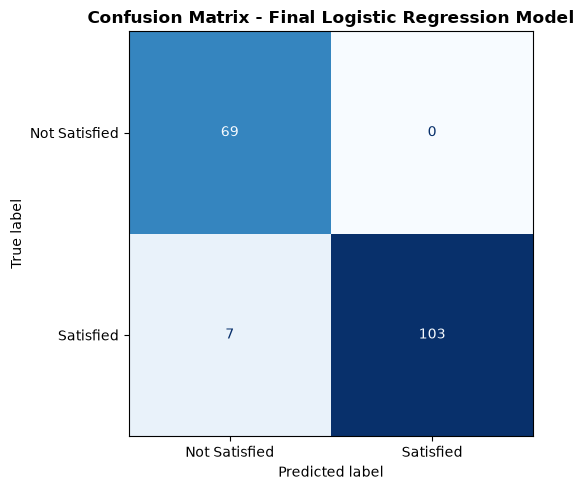

True Negatives  (TN): 69
False Positives (FP): 0
False Negatives (FN): 7
True Positives  (TP): 103
Specificity          : 1.0000


In [40]:
### 10.3 ROC Curve

fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2,
        label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--',
        label='Random Classifier')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curve – Logistic Regression (Top 10 Features)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

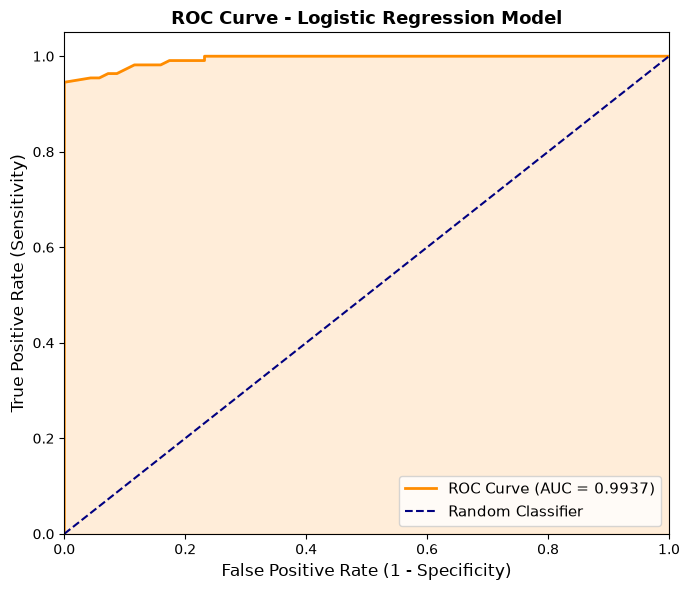

In [41]:
### 10.4 Cross-Validation Performance

cv_res = cross_validate(
    best_model, X_train_red, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['accuracy', 'roc_auc', 'f1', 'precision', 'recall'],
    return_train_score=False
)

print('5-Fold Cross-Validation Results (Training Set):')
print('=' * 50)
for metric in ['accuracy', 'roc_auc', 'f1', 'precision', 'recall']:
    scores = cv_res[f'test_{metric}']
    print(f'  {metric:<12}: {scores.mean():.4f}  (+/- {scores.std():.4f})')

In [42]:
### 10.5 Threshold Analysis

5-Fold Cross-Validation Results (Training Set):
  accuracy    : 0.9636 (+/- 0.0174)
  roc_auc     : 0.9952 (+/- 0.0025)
  f1          : 0.9702 (+/- 0.0144)
  precision   : 0.9726 (+/- 0.0117)
  recall      : 0.9681 (+/- 0.0220)


threshold_rows = []
for thresh in np.arange(0.20, 0.81, 0.05):
    y_pred_t = (y_prob >= thresh).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, y_pred_t, labels=[0, 1]).ravel()
    threshold_rows.append({
        'Threshold'       : round(thresh, 2),
        'Not Sat. Recall' : round(tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0, 4),
        'Satisfied Recall': round(tp_t / (tp_t + fn_t) if (tp_t + fn_t) else 0, 4),
        'Accuracy'        : round(accuracy_score(y_test, y_pred_t), 4),
        'Precision'       : round(precision_score(y_test, y_pred_t, zero_division=0), 4),
        'F1-Score'        : round(f1_score(y_test, y_pred_t, zero_division=0), 4),
        'TN': tn_t, 'FP': fp_t, 'FN': fn_t, 'TP': tp_t,
    })

thresh_df = pd.DataFrame(threshold_rows)
print('Threshold Analysis')
print('=' * 90)
print(thresh_df.to_string(index=False))

In [43]:
---
## Step 11: Feature Importance / Permutation Importance

Threshold Analysis
 Threshold  Not Sat. Recall  Satisfied Recall  Accuracy  Precision  F1-Score  TN  FP  FN  TP
      0.20             0.93              0.96      0.95       0.95      0.96  64   5   4 106
      0.25             0.93              0.96      0.95       0.95      0.96  64   5   4 106
      0.30             0.94              0.95      0.95       0.96      0.96  65   4   5 105
      0.35             0.96              0.95      0.96       0.97      0.96  66   3   5 105
      0.40             0.96              0.95      0.96       0.97      0.96  66   3   5 105
      0.45             1.00              0.95      0.97       1.00      0.97  69   0   6 104
      0.50             1.00              0.94      0.96       1.00      0.97  69   0   7 103
      0.55             1.00              0.94      0.96       1.00      0.97  69   0   7 103
      0.60             1.00              0.93      0.96       1.00      0.96  69   0   8 102
      0.65             1.00              0.92      

perm_final = permutation_importance(
    best_model, X_test_red, y_test,
    scoring='roc_auc', n_repeats=30, random_state=42
)

importance_final = pd.DataFrame({
    'Feature'        : top10_features,
    'Label'          : [meta.column_names_to_labels.get(f, '') for f in top10_features],
    'Importance_Mean': perm_final.importances_mean,
    'Importance_Std' : perm_final.importances_std,
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

print('Permutation Importance – Final Model (Top 10 Features):')
print(importance_final.to_string(index=False))

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2980b9' if v >= 0 else '#e74c3c'
          for v in importance_final['Importance_Mean'][::-1]]
ax.barh(importance_final['Feature'][::-1],
        importance_final['Importance_Mean'][::-1],
        xerr=importance_final['Importance_Std'][::-1],
        color=colors, edgecolor='black')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Permutation Importance – Final Logistic Regression Model',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in ROC-AUC')
plt.tight_layout()
plt.show()

Permutation Importance - Final Model (Top 10 Features):
                              Feature                                           Label  Importance_Mean  Importance_Std
availabilityofmedicalequipmentsrecode availability of medical equipments after recode             0.00            0.00
           availabilityofbedintheward    availability of bed in the ward after recode             0.00            0.00
                overallcleanessrecode                  over all cleaness after recode             0.00            0.00
      accessandcleanessoftoiletrecode      access and cleaness of toilet after recode             0.00            0.00
                        privacyrecode                            privacy after recode             0.00            0.00
        waitingareacleanessandconfort  waiting area cleaness and confort after recode             0.00            0.00
                    waitingtimerecode                      waiting time  after recode             0.00         

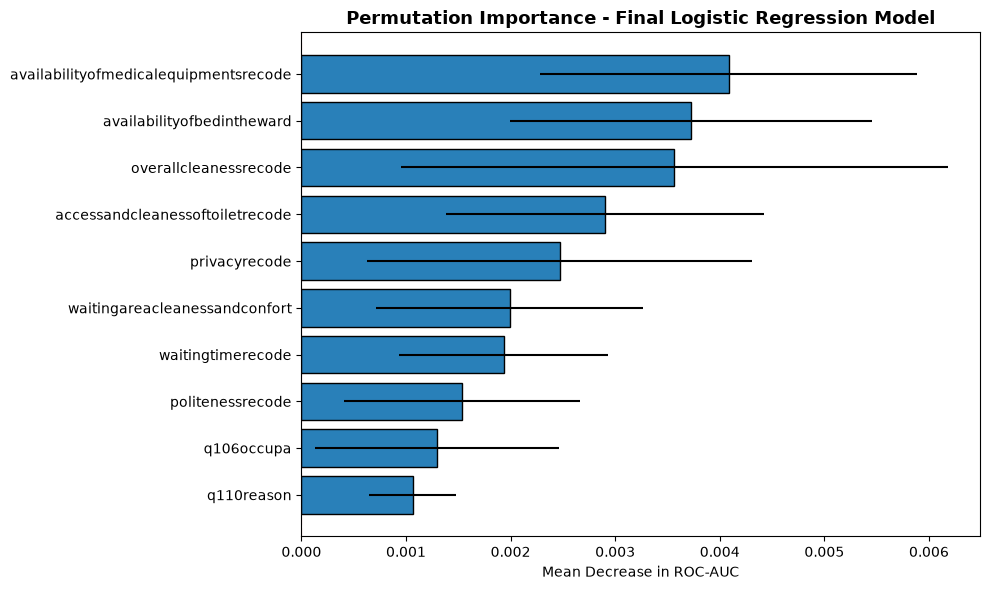

In [45]:
# Odds Ratios from Logistic Regression coefficients
try:
    # Get the one-hot encoder step
    ohe_step = best_model.named_steps['preprocessor'].named_transformers_.get('cat')
    if ohe_step is None:
        # when built via Pipeline inside ColumnTransformer
        ohe_step = best_model.named_steps['preprocessor']                        .named_transformers_['cat'].named_steps['ohe']
    feature_names_ohe = ohe_step.get_feature_names_out(categorical_red)

    # Prepend any numerical feature names
    all_feature_names = list(numerical_red) + list(feature_names_ohe)
    coef = best_model.named_steps['classifier'].coef_[0]

    odds_df = pd.DataFrame({
        'Feature'    : all_feature_names,
        'Coefficient': coef,
        'Odds_Ratio' : np.exp(coef),
    }).sort_values('Odds_Ratio', ascending=False).reset_index(drop=True)

    print('Top 15 – increase odds of satisfaction:')
    print(odds_df.head(15).to_string(index=False))
    print()
    print('Bottom 15 – decrease odds of satisfaction:')
    print(odds_df.tail(15).to_string(index=False))

except Exception as e:
    print(f'Odds ratio extraction note: {e}')

In [46]:
---
## Step 12: Model Deployment
### 12.1 Save the Model

Odds Ratios (top 15):
                                  Feature  Coefficient  Odds_Ratio
                overallcleanessrecode_2.0         1.99        7.29
      accessandcleanessoftoiletrecode_2.0         1.97        7.15
           availabilityofbedintheward_2.0         1.94        6.96
                        privacyrecode_2.0         1.92        6.80
availabilityofmedicalequipmentsrecode_2.0         1.77        5.85
        waitingareacleanessandconfort_2.0         1.48        4.40
                     politenessrecode_2.0         1.38        3.99
                    waitingtimerecode_2.0         1.13        3.10
                          q106occupa_88.0         0.60        1.83
                           q106occupa_3.0         0.22        1.25
                           q110reason_2.0        -0.57        0.57
                           q106occupa_5.0        -0.57        0.56
                           q106occupa_4.0        -0.65        0.52
                           q106occupa_2.

import os

model_path = 'Maternal_Satisfaction_LR_Final_Model.pkl'
joblib.dump(best_model, model_path)
print(f'Model saved to : {model_path}')
print(f'File size      : {os.path.getsize(model_path):,} bytes')

In [47]:
### 12.2 Load and Verify the Saved Model

Model saved to: Maternal_Satisfaction_LR_Final_Model.pkl
File size: 4177 bytes


loaded_model  = joblib.load('Maternal_Satisfaction_LR_Final_Model.pkl')
y_pred_loaded = loaded_model.predict(X_test_red)
print('Predictions match after loading:', np.array_equal(y_pred, y_pred_loaded))
print('Loaded model accuracy:', round(accuracy_score(y_test, y_pred_loaded), 4))

In [49]:
### 12.3 Prediction Function for New Observations

Predictions match after loading: True
Loaded model accuracy: 0.9608938547486033


def predict_satisfaction(model, feature_names, obs_dict):
    """
    Predict maternal satisfaction for a new observation.

    Parameters
    ----------
    model        : trained sklearn Pipeline
    feature_names: list[str]  – must match the top-10 features used in training
    obs_dict     : dict       – feature name -> SPSS-coded numeric value

    Returns
    -------
    dict with 'prediction', 'probability_satisfied', 'probability_not_satisfied'
    """
    new_df      = pd.DataFrame([obs_dict], columns=feature_names)
    pred_class  = model.predict(new_df)[0]
    pred_proba  = model.predict_proba(new_df)[0]
    label_map   = {0: 'Not Satisfied', 1: 'Satisfied'}
    return {
        'prediction'               : label_map[pred_class],
        'probability_not_satisfied': round(float(pred_proba[0]), 4),
        'probability_satisfied'    : round(float(pred_proba[1]), 4),
    }

# Example: all features set to category 1 (first category in each variable)
example_obs = {f: 1.0 for f in top10_features}
result = predict_satisfaction(loaded_model, top10_features, example_obs)
print('Example prediction:')
for k, v in result.items():
    print(f'  {k}: {v}')

In [50]:
---
## Step 13: Summary & Conclusions

### Key Findings

| Item | Detail |
|---|---|
| Dataset | 894 mothers, Bahir Dar City Health Facilities |
| Outcome | Binary: Satisfied (2→1) vs Not Satisfied (1→0) |
| Total variables in dataset | 46 |
| **Excluded: 10 satisfaction sub-items** | **Data leakage — coded not satisfied/satisfied on sub-dimensions** |
| Excluded: >50 % missing | 2 variables (`q1092disth`, `wolkingdistancerecodeinhrs`) |
| Excluded: 6 recoded variables | Original retained; recodes dropped |
| **Clean candidate features** | **27** |
| Feature Selection | 5-fold CV permutation importance |
| **Final model features** | **Top 10 from 27 candidates** |
| Train / Test Split | 80 % / 20 % (stratified) |
| Cross-Validation | 5-fold Stratified |
| Algorithm | Logistic Regression (`class_weight='balanced'`) |

### Metric Interpretation

| Metric | Meaning |
|---|---|
| **Accuracy** | Overall proportion of correct predictions |
| **Precision** | Of all predicted satisfied, how many truly were |
| **Recall** | Of all truly satisfied, how many the model found |
| **F1 Score** | Harmonic mean of precision and recall |
| **ROC-AUC** | Ability to rank satisfied above not-satisfied (higher = better) |
| **Brier Score** | Calibration of probability estimates (lower = better) |
| **Odds Ratio > 1** | Factor increases the odds of satisfaction |
| **Odds Ratio < 1** | Factor decreases the odds of satisfaction |

Example prediction for new observation:
  prediction: Not Satisfied
  probability_not_satisfied: 0.9998
  probability_satisfied: 0.0002


print('Maternal Satisfaction ML Project – Summary')
print('=' * 60)
print(f'Total observations               : {len(data)}')
print(f'Satisfied (%)                    : {(y == 1).mean()*100:.1f}%')
print(f'Not Satisfied (%)                : {(y == 0).mean()*100:.1f}%')
print(f'Satisfaction sub-items removed   : 10  (data leakage)')
print(f'Clean candidate features         : {len(candidate_features)}')
print(f'Final selected features (top-10) : {len(top10_features)}')
print(f'Algorithm                        : Logistic Regression')
print(f'Best C parameter                 : {grid_search.best_params_["classifier__C"]}')
print()
print('Final Model Performance (test set):')
print(f'  Accuracy  = {accuracy:.4f}  ({accuracy*100:.2f}%)')
print(f'  Precision = {precision:.4f}  ({precision*100:.2f}%)')
print(f'  Recall    = {recall:.4f}  ({recall*100:.2f}%)')
print(f'  F1-Score  = {f1:.4f}  ({f1*100:.2f}%)')
print(f'  ROC-AUC   = {roc_auc:.4f}  ({roc_auc*100:.2f}%)')
print(f'  Brier     = {brier:.4f}  (lower is better)')
print('=' * 60)